In [ ]:
id1 = 465421
id2 = 466811
s1 = (id1 + id2) % 6 + 1
sid1 = sum(map(int, list(str(id1))))
sid2 = sum(map(int, list(str(id2))))
s2 = (sid1 + sid2) % 3 + 1

print("Задача 1 - вариант " + str(s1))
print("Задача 2 - вариант " + str(s2))

## Вариант 1
Методом моментов найти оценку параметра $\theta$ равномерного, распределения на $[-\theta, \theta]$. Эксперимент при $\theta = 10$.

### Метод моментов
$X_1, X_2, ..., X_n \sim U[-\theta, \theta], \theta > 0$. Вместо $\theta$, оценим параметр $\theta^2$ 

Первый момент величины $X^2$:
$$p(x) = \frac1{2\theta} \bold{1}(|x|\le\theta)$$
$$EX^2 = \int_{-\theta}^{\theta} x^2 * p(x) dx = \frac{\theta^2}3$$

Посчитаем также второй момент $X^2$: $ EX^4 = \frac{\theta^4}5 $ 

Итоговая оценка: $\hat{\theta^2} = 3*\overline{X^2}$

### Свойства оценки

$E[\widehat{\theta^2}]=\frac3n\sum_{i=1}^nE[X_i^2]=\theta^2$ - оценка несмещена

$Bias(\widehat{\theta^2}) = 0$, поэтому

$MSE(\widehat{\theta^2}) = Var(\widehat{\theta^2}) = \frac{9}n (\frac{\theta^4}5 - \frac{\theta^4}{9}) = \frac{4\theta^4}{5n}$

По закону больших чисел $\widehat{\theta^2} = 3\overline{X^2} \rightarrow \theta^2$ - оценка состоятельна

По ЦПТ $\sqrt{n}(\widehat{\theta^2} - \theta^2) \xrightarrow{d} N(0, \frac{4\theta^4}5)$ - асимптотическая нормальность


    n        mean         var        bias         mse   count   fraction
------------------------------------------------------------------------
   10   99.724276  811.786662   -0.275724  811.862686     848     0.8480
   50   99.711395  168.358993   -0.288605  168.442286     696     0.6960
  100  100.328705   79.257156    0.328705   79.365203     563     0.5630
  500   99.934673   15.525366   -0.065327   15.529634     193     0.1930
 1000   99.953518    8.701858   -0.046482    8.704018      89     0.0890
 5000  100.043291    1.609117    0.043291    1.610991       0     0.0000
10000   99.945435    0.747332   -0.054565    0.750309       0     0.0000
50000   99.986970    0.167739   -0.013030    0.167909       0     0.0000


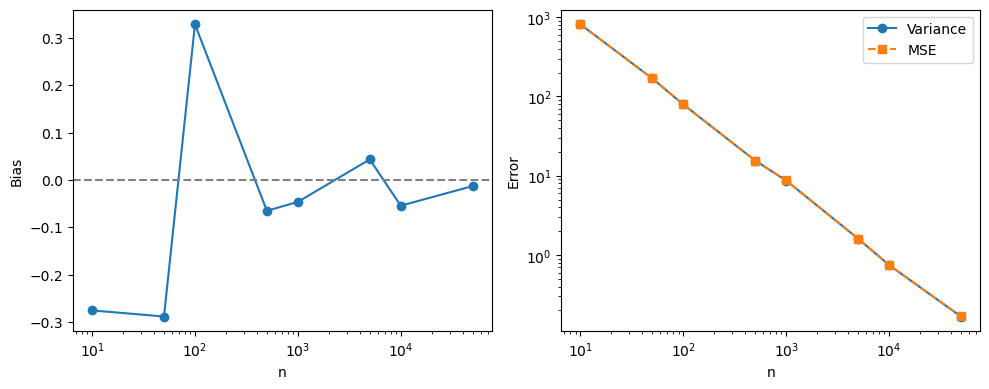

In [81]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(6767)

sizes = [10, 50, 100, 500, 1000, 5000, 10000, 50000]
m = 1000
theta = 10
eps = 5 # threshold

biases, varianses, mses = [], [], []

print(f"{'n':>5} {'mean':>11} {'var':>11} {'bias':>11} {'mse':>11} {'count':>7} {'fraction':>10}")
print("-"*72)
for n in sizes:
    samples = rng.uniform(-theta, theta, (m, n))
    est = 3 * (samples**2).mean(axis=1)
    errors = est - theta**2
    count = np.count_nonzero(np.abs(errors) > eps)
    fraction = count / m
    bias = errors.mean()
    var = est.var()
    mse = np.mean(errors**2)
    biases.append(bias)
    varianses.append(var)
    mses.append(mse)

    print(f"{n:5d} {est.mean():11.6f} {var:11.6f} {bias:11.6f} {mse:11.6f} {count:7d} {fraction:10.4f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].semilogx(sizes, biases, "o-")
axes[0].axhline(0, color="gray", linestyle="--")
axes[0].set(xlabel="n", ylabel="Bias")

axes[1].loglog(sizes, varianses, "o-", label="Variance")
axes[1].loglog(sizes, mses, "s--", label="MSE")
axes[1].set(xlabel="n", ylabel="Error")
axes[1].legend()

plt.tight_layout()
plt.show()


### Интерпретация результатов

Из результатов эксперимента видно, что среднее оценок $\verb|mean|$ находится около $100$, что согласуется с несмещенностью оценки. Теоретическое смещение равно 0 при любом $n$. Эмпирическое смещение колеблется около нуля из-за конечного числа повторений. Теоретические $\verb|Var|$ и $\verb|MSE|$ совпадают и равны $8000/n$. Эмпирический $\verb|Var|$ близок к $\verb|MSE|$ и они оба стремятся к 0. Количество выборок $\verb|count|$, ошибка которых превышает выбранный порог $\verb|eps| = 5$, а также их доля $\verb|fraction|$ уменьшаются с увеличением $n$. 

# Задача 2


## Найдем апостериорную плотность

$$
\pi(\theta \mid X) =
\frac{L(X \mid \theta)\pi(\theta)}
{\displaystyle\int_0^{+\infty} L(X \mid t)\pi(t)\,dt}
$$

$$
X_i \sim \operatorname{Pois}(\theta),
\qquad
\theta \sim \Gamma(k,\lambda)
$$

$$
S=\sum_{i=1}^n X_i
$$

### Числитель
$$
\begin{aligned}
L(X\mid\theta)
&= \prod_{i=1}^n P(X_i=x_i\mid\theta) \\
&= \prod_{i=1}^n \frac{\theta^{x_i}e^{-\theta}}{x_i!} \\
&= \frac{\theta^S e^{-n\theta}}{\prod_{i=1}^n x_i!}
\end{aligned}
$$

$$
\pi(\theta)=
\frac{\lambda^k}{\Gamma(k)}
\theta^{k-1}e^{-\lambda\theta}
$$

$$
L(X\mid\theta)\pi(\theta)
=
\frac{\lambda^k}{\Gamma(k)\prod X_i!}
\theta^{S+k-1}e^{-(n+\lambda)\theta}
$$

$$
L(X\mid\theta)\pi(\theta)
=
C\theta^{S+k-1}e^{-(n+\lambda)\theta}
$$

$C$ есть и снизу так что оно сократится

### Знаменатель
$$
\begin{aligned}
\int_0^{+\infty} L(X\mid t)\pi(t)\,dt
&=
\int_0^{+\infty}
Ct^{S+k-1}e^{-(n+\lambda)t}\,dt
\\
&=
C\int_0^{+\infty}
t^{S+k-1}e^{-(n+\lambda)t}\,dt
\end{aligned}
$$

пользуясь

$$
\begin{aligned}
\int_0^{+\infty}t^{z-1}e^{-bt}\,dt
&=
\int_0^{+\infty}
\left(\frac{u}{b}\right)^{z-1}e^{-u}\frac{du}{b}
\\
&=
\frac{1}{b^z}\int_0^{+\infty}u^{z-1}e^{-u}\,du
\\
&=
\frac{\Gamma(z)}{b^z}
\end{aligned}
$$

при условии

$$
z=S+k,\qquad b=n+\lambda
$$

знаменатель равен:

$$
C\frac{\Gamma(S+k)}{(n+\lambda)^{S+k}}
$$

### Итоговая плотность
$$
\begin{aligned}
\pi(\theta\mid X)
&=
\frac{C\theta^{S+k-1}e^{-(n+\lambda)\theta}}
{C\frac{\Gamma(S+k)}{(n+\lambda)^{S+k}}}
\\[8pt]
&=
\frac{\theta^{S+k-1}e^{-(n+\lambda)\theta}}
{\frac{\Gamma(S+k)}{(n+\lambda)^{S+k}}}
\\[8pt]
&=
\frac{(n+\lambda)^{S+k}}{\Gamma(S+k)}
\theta^{S+k-1}e^{-(n+\lambda)\theta}
\end{aligned}
$$

А это очень похоже на плотность гамма-распределения с

$$
\lambda' = n + \lambda, \qquad k' = S + k
$$

то есть

$$
\theta \mid X \sim \Gamma(S+k, n+\lambda)
$$



## Найдем байесовские оценки

$$
\hat\theta_B=
\arg\min_{\hat\theta}
\mathbb E[l(\hat\theta,\theta)\mid X]
$$

### Квадратичная функция потерь

По доказанному

$$
\hat\theta_B^{(2)}=\mathbb E[\theta\mid X]
$$

Причем так как
$$
\theta \mid X \sim \Gamma(S+k, n+\lambda)
$$
то
$$
\mathbb E[\theta\mid X] = \frac{k'}{\lambda'} = \frac{S + k}{n + \lambda}
$$

### Абсолютная функция потерь
$$
l(\hat\theta,\theta)=|\hat\theta-\theta|
$$

$$
\hat\theta_B^{(abs)}
=
\arg\min_{\hat\theta}
\int_0^\infty
|\hat\theta-\theta|\pi(\theta\mid X)\,d\theta
=
\arg\min_{\hat\theta} I(\hat\theta)
$$

$$
\begin{aligned}
I(\hat\theta)
&=\int_0^{\hat\theta}
(\hat\theta-\theta)\pi(\theta\mid X)\,d\theta\\
&+\int_{\hat\theta}^\infty
(\theta-\hat\theta)\pi(\theta\mid X)\,d\theta.
\end{aligned}
$$

дифференцируем по Лейбницу

$$
\begin{aligned}
I'(\hat\theta)
&=
\int_0^{\hat\theta}\pi(\theta\mid X)\,d\theta
-
\int_{\hat\theta}^\infty\pi(\theta\mid X)\,d\theta\\
&=F(\hat\theta\mid X)-(1-F(\hat\theta\mid X))\\
&=2F(\hat\theta\mid X)-1
\end{aligned}
$$

где $F$ — функция распределения. Приравняем к нулю

$$
2F(\hat\theta\mid X)-1=0
$$

$$
F(\hat\theta\mid X)=\frac12
$$

$$
\hat\theta_B^{(abs)}
=\operatorname{Med}(\theta\mid X)
$$


## Найдем оценку максимального правдоподобия
$$
\hat\theta_{\mathrm{MLE}}=
\arg\max_{\theta}L(X\mid\theta)
$$

прологарифмируем и возьмем производную

$$
\ln L(X\mid\theta)
=
S\ln\theta-n\theta-\sum_{i=1}^n\ln(X_i!)
$$

$$
\frac{\partial\ln L}{\partial\theta}
=
\frac{S}{\theta}-n
$$

вторая производная будет отрицательной при $S>0$ значит корень - точка максимума

$$
\frac{\partial^2\ln L}{\partial\theta^2}
=
-\frac{S}{\theta^2}<0
$$

$$
\frac{S}{\theta}-n=0
$$

$$
\hat\theta_{\mathrm{MLE}}=\frac{S}{n}=\overline X
$$

В случае квадратичной функции ошибки их разница стремится к нулю при $n\to\infty$:

$$
\hat\theta_B^{(sq)}-\hat\theta_{\mathrm{MLE}}
=
\frac{S+k}{n+\lambda}-\frac{S}{n}
=
\frac{nk-\lambda S}{n(n+\lambda)}
\xrightarrow[n\to\infty]{}0
$$

В случае абсолютной ошибки - разница между апостериорной медианой и выборочным средним которая тоже стремится к нулю при $n\to\infty$:

$$
\hat\theta_B^{(abs)}-\hat\theta_{\mathrm{MLE}}
=
\operatorname{Med}(\theta\mid X)-\overline X
\xrightarrow[n\to\infty]{}0
$$

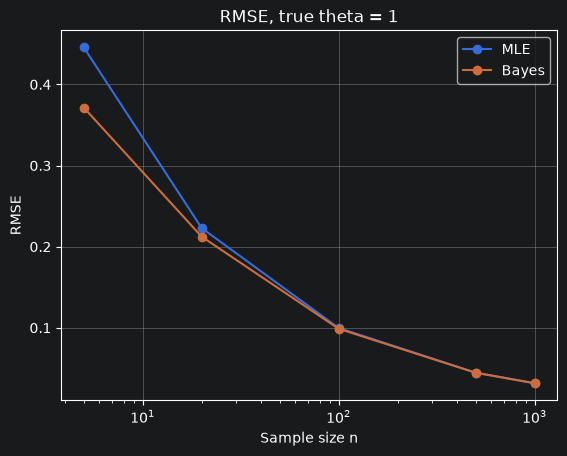

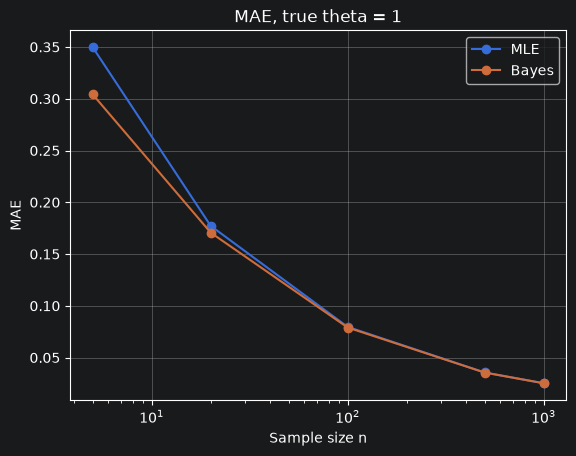

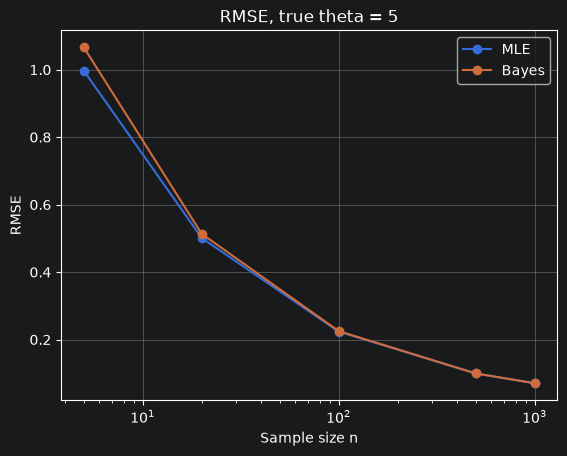

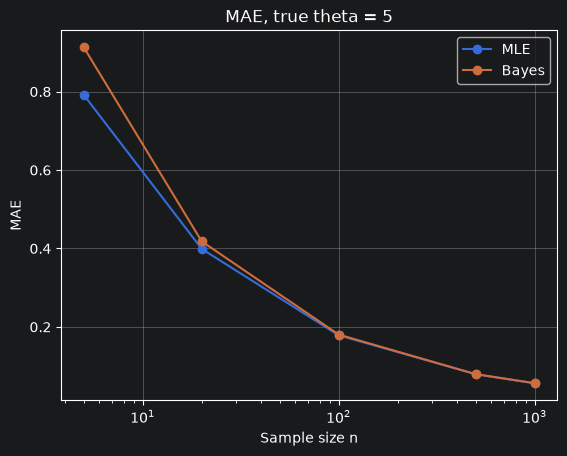

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy

rng = np.random.default_rng(67676767)

ns = [5, 20, 100, 500, 1000]
repeats = 100_000

for theta in [1, 5]:
    rmse_mle, rmse_bayes = [], []
    mae_mle, mae_bayes = [], []

    for n in ns:
        X = rng.poisson(theta, size=(repeats, n))
        S = np.sum(X, axis=1)

        # оценка максимального правдоподобия
        mle = S / n

        # байесовская оценка квадратичной ошибки
        bayes_sq = (S + 1) / (n + 1)

        # байесовская оценка  абсолютной ошибки
        bayes_abs = scipy.stats.gamma.ppf( 0.5, a=S + 1, scale=1 / (n + 1))

        rmse_mle.append(np.sqrt(np.mean((mle - theta)**2)))
        rmse_bayes.append(np.sqrt(np.mean((bayes_sq - theta)**2)))

        mae_mle.append(np.mean(np.abs(mle - theta)))
        mae_bayes.append(np.mean(np.abs(bayes_abs - theta)))

    for metric, mle_errors, bayes_errors in [
        ("RMSE", rmse_mle, rmse_bayes),
        ("MAE", mae_mle, mae_bayes),]:
        plt.figure()
        plt.plot(ns, mle_errors, "o-", label="MLE")
        plt.plot(ns, bayes_errors, "o-", label="Bayes")
        plt.xlabel("Sample size n")
        plt.ylabel(metric)
        plt.title(f"{metric}, true theta = {theta}")
        plt.xscale("log")
        plt.grid(True)
        plt.legend()
        plt.show()
